# 02 Procesamiento de texto, recuperación secuencial e indexación

## Objetivo

Implementar y comparar dos mecanismos de recuperación de información —búsqueda secuencial e índice invertido— sobre colecciones de libros del Proyecto Gutenberg, investigando experimentalmente su rendimiento y escalabilidad.

### Parte A. Corpus pequeño

**1. Preparación del corpus**

Utilice los 18 documentos de la colección Gutenberg disponible en NLTK.

1. Cargue los textos originales.
2. Identifique el número de documentos y sus tamaños.
3. Implemente tokenización y normalización: conversión a minúsculas, tratamiento de puntuación y caracteres especiales.

Seleccione y documente una configuración de preprocesamiento que se utilizará consistentemente en todos los experimentos.

In [40]:
import nltk
import re
import string
import time
import statistics
import os
import tarfile
import zipfile
import glob
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from collections import defaultdict
from nltk.corpus import gutenberg

nltk.download('gutenberg')

# Cargar los 18 documentos
documentos_originales = {
    nombre: gutenberg.raw(nombre)
    for nombre in gutenberg.fileids()
}

# Normalización: minúsculas, eliminación de puntuación
# y conservación de letras y números
def tokenizar(texto):
    texto = texto.lower()
    return re.findall(r'\b[a-z0-9]+\b', texto)

documentos = {
    nombre: tokenizar(texto)
    for nombre, texto in documentos_originales.items()
}

print("Número de documentos:", len(documentos))

tabla_tamanos = pd.DataFrame([
    {
        "Documento": nombre,
        "Caracteres": len(texto),
        "Tokens": len(documentos[nombre])
    }
    for nombre, texto in documentos_originales.items()
])

display(tabla_tamanos)
print("Total de tokens:", sum(len(t) for t in documentos.values()))
from pathlib import Path

[nltk_data] Downloading package gutenberg to
[nltk_data]     C:\Users\HANDRESTH\AppData\Roaming\nltk_data...
[nltk_data]   Package gutenberg is already up-to-date!


Número de documentos: 18


,Documento,Caracteres,Tokens
0,austen-emma.txt,887071,161612
1,austen-persuasion.txt,466292,84167
2,austen-sense.txt,673022,120787
3,bible-kjv.txt,4332554,854046
4,blake-poems.txt,38153,6936
5,bryant-stories.txt,249439,46613
6,burgess-busterbrown.txt,84663,16332
7,carroll-alice.txt,144395,27334
8,chesterton-ball.txt,457450,82767
9,chesterton-brown.txt,406629,73288


Total de tokens: 2198599


**2. Búsqueda secuencial**

Implemente una función que reciba un término de consulta y devuelva los identificadores de todos los documentos que lo contienen con una búsqueda secuencial.

La implementación deberá utilizar obligatoriamente dos lazos `for` anidados: el primero recorre los documentos y el segundo los tokens de cada documento.

No es necesario utilizar índices invertidos, motores de búsqueda ni estructuras auxiliares que almacenen anticipadamente los documentos asociados a cada término.

Ejecute consultas con términos frecuentes, poco frecuentes e inexistentes.

In [41]:
def _busqueda_secuencial_token(termino, documentos):
    resultados = []
    for id_documento, tokens in documentos.items():
        for token in tokens:
            if token == termino:
                resultados.append(id_documento)
                break
    return resultados

def busqueda_secuencial(consulta, documentos):
    terminos = tokenizar(consulta)
    if not terminos:
        return []
    return _busqueda_secuencial_token(terminos[0], documentos)

consultas = ["the", "love", "is", "war", "VientoOO"]
for consulta in consultas:
    resultado = busqueda_secuencial(consulta, documentos)
    print(f"Consulta: {consulta}")
    print(f"Documentos encontrados: {len(resultado)}")
    print(resultado)
    print()

Consulta: the
Documentos encontrados: 18
['austen-emma.txt', 'austen-persuasion.txt', 'austen-sense.txt', 'bible-kjv.txt', 'blake-poems.txt', 'bryant-stories.txt', 'burgess-busterbrown.txt', 'carroll-alice.txt', 'chesterton-ball.txt', 'chesterton-brown.txt', 'chesterton-thursday.txt', 'edgeworth-parents.txt', 'melville-moby_dick.txt', 'milton-paradise.txt', 'shakespeare-caesar.txt', 'shakespeare-hamlet.txt', 'shakespeare-macbeth.txt', 'whitman-leaves.txt']

Consulta: love
Documentos encontrados: 15
['austen-emma.txt', 'austen-persuasion.txt', 'austen-sense.txt', 'bible-kjv.txt', 'blake-poems.txt', 'bryant-stories.txt', 'burgess-busterbrown.txt', 'carroll-alice.txt', 'chesterton-ball.txt', 'chesterton-brown.txt', 'chesterton-thursday.txt', 'edgeworth-parents.txt', 'melville-moby_dick.txt', 'milton-paradise.txt', 'whitman-leaves.txt']

Consulta: is
Documentos encontrados: 18
['austen-emma.txt', 'austen-persuasion.txt', 'austen-sense.txt', 'bible-kjv.txt', 'blake-poems.txt', 'bryant-stori

**3. Medición de tiempos de ejecución**

Utilice `time.perf_counter_ns()` o una herramienta de medición equivalente para obtener el tiempo de ejecución de las consultas.

Cada medición deberá corresponder a **30 ejecuciones de la misma consulta**. Y se debe calcular la media aritmética.

Registre los resultados en milisegundos. No incluya la carga de archivos ni la tokenización dentro del tiempo de consulta.

In [42]:
def medir_tiempo(funcion, *args, repeticiones=30):
    tiempos = []

    for _ in range(repeticiones):
        inicio = time.perf_counter_ns()
        funcion(*args)
        fin = time.perf_counter_ns()

        tiempos.append((fin - inicio) / 1_000_000)

    return statistics.mean(tiempos)


resultados_secuencial = []

for consulta in consultas:
    tiempo_ms = medir_tiempo(
        _busqueda_secuencial_token, tokenizar(consulta)[0], documentos
    )

    resultados_secuencial.append({
        "Consulta": consulta,
        "Método": "Secuencial",
        "Tiempo medio (ms)": tiempo_ms,
        "Ejecuciones": 30
    })

df_secuencial = pd.DataFrame(resultados_secuencial)
display(df_secuencial)

,Consulta,Método,Tiempo medio (ms),Ejecuciones
0,the,Secuencial,0.008563,30
1,love,Secuencial,4.629983,30
2,is,Secuencial,0.184630,30
3,war,Secuencial,16.630270,30
4,VientoOO,Secuencial,74.754560,30


**4. Construcción del índice invertido**

Implemente un índice invertido que contenga el vocabulario de la colección y las listas de documentos asociados a cada término.

Inspeccione las listas de postings y calcule la frecuencia documental (DF) de varios términos.

Implemente consultas de un término y consultas booleanas con AND, OR y NOT.

In [43]:
def construir_indice(documentos):
    indice = defaultdict(set)
    for id_documento, tokens in documentos.items():
        for token in set(tokens):
            indice[token].add(id_documento)
    return dict(indice)

indice = construir_indice(documentos)
print("Términos únicos:", len(indice))

for termino in ["the", "love", "is", "war", "VientoOO"]:
    postings = sorted(indice.get(termino.lower(), set()))
    print(f"\nTérmino: {termino}")
    print("Postings:", postings)
    print("DF:", len(postings))


def _busqueda_indice_token(termino, indice):
    return sorted(indice.get(termino, set()))


def busqueda_indice(consulta, indice):
    terminos = tokenizar(consulta)
    if not terminos:
        return []
    return _busqueda_indice_token(terminos[0], indice)


# Operaciones booleanas

def consulta_and(termino1, termino2, indice):
    tokens1 = tokenizar(termino1)
    tokens2 = tokenizar(termino2)
    if not tokens1 or not tokens2:
        return []
    return sorted(indice.get(tokens1[0], set()) & indice.get(tokens2[0], set()))


def consulta_or(termino1, termino2, indice):
    tokens1 = tokenizar(termino1)
    tokens2 = tokenizar(termino2)
    if not tokens1 or not tokens2:
        return []
    return sorted(indice.get(tokens1[0], set()) | indice.get(tokens2[0], set()))


def consulta_not(termino, documentos, indice):
    tokens = tokenizar(termino)
    if not tokens:
        return sorted(documentos.keys())
    return sorted(set(documentos.keys()) - indice.get(tokens[0], set()))


print("\nAND:", consulta_and("love", "the", indice))
print("\nOR:", consulta_or("love", "the", indice))
print("\nNOT:", consulta_not("love", documentos, indice))

Términos únicos: 41816

Término: the
Postings: ['austen-emma.txt', 'austen-persuasion.txt', 'austen-sense.txt', 'bible-kjv.txt', 'blake-poems.txt', 'bryant-stories.txt', 'burgess-busterbrown.txt', 'carroll-alice.txt', 'chesterton-ball.txt', 'chesterton-brown.txt', 'chesterton-thursday.txt', 'edgeworth-parents.txt', 'melville-moby_dick.txt', 'milton-paradise.txt', 'shakespeare-caesar.txt', 'shakespeare-hamlet.txt', 'shakespeare-macbeth.txt', 'whitman-leaves.txt']
DF: 18

Término: love
Postings: ['austen-emma.txt', 'austen-persuasion.txt', 'austen-sense.txt', 'bible-kjv.txt', 'blake-poems.txt', 'bryant-stories.txt', 'burgess-busterbrown.txt', 'carroll-alice.txt', 'chesterton-ball.txt', 'chesterton-brown.txt', 'chesterton-thursday.txt', 'edgeworth-parents.txt', 'melville-moby_dick.txt', 'milton-paradise.txt', 'whitman-leaves.txt']
DF: 15

Término: is
Postings: ['austen-emma.txt', 'austen-persuasion.txt', 'austen-sense.txt', 'bible-kjv.txt', 'blake-poems.txt', 'bryant-stories.txt', 'burges

**5. Comparación**

Ejecute las mismas consultas con ambos métodos.

Compruebe que recuperan exactamente los mismos identificadores de documentos y mida el tiempo medio de 30 ejecuciones para cada consulta y método.

In [44]:
resultados_comparacion = []

for consulta in consultas:
    secuencial = set(busqueda_secuencial(consulta, documentos))
    invertido = set(busqueda_indice(consulta, indice))

    resultados_comparacion.append({
        "Consulta": consulta,
        "Coinciden": secuencial == invertido,
        "Documentos encontrados": len(secuencial),
        "Tiempo secuencial (ms)": medir_tiempo(
            _busqueda_secuencial_token, tokenizar(consulta)[0], documentos
        ),
        "Tiempo índice (ms)": medir_tiempo(
            _busqueda_indice_token, tokenizar(consulta)[0], indice
        )
    })

df_comparacion = pd.DataFrame(resultados_comparacion)
display(df_comparacion)

assert df_comparacion["Coinciden"].all(), \
    "Error: los métodos no recuperan los mismos documentos."

,Consulta,Coinciden,Documentos encontrados,Tiempo secuencial (ms),Tiempo índice (ms)
0,the,True,18,0.008550,0.001077
1,love,True,15,6.096387,0.001067
2,is,True,18,0.118047,0.001017
3,war,True,10,14.394787,0.001043
4,VientoOO,True,0,74.927270,0.000740


### Parte B. Corpus grande

**6. Descarga de Gutenberg**

Descargue el archivo oficial `txt-files.tar.zip`, de aproximadamente 11 GB, desde:

https://www.gutenberg.org/cache/epub/feeds/

Identifique los archivos TXT, evite contar distintas versiones del mismo libro como documentos independientes y registre la cantidad de documentos válidos.

In [45]:
CARPETA = Path.cwd()
RUTA_ZIP = CARPETA / "txt-files.tar.zip"

In [46]:
with zipfile.ZipFile(RUTA_ZIP, "r") as zf:
    nombres_zip = zf.namelist()

    txt_directos = [
        n for n in nombres_zip
        if n.lower().endswith(".txt")
        and not n.endswith("/")
    ]

    tar_interno = next(
        (n for n in nombres_zip if n.lower().endswith(".tar")),
        None
    )

    if txt_directos:
        tipo_archivo = "zip_txt"
        nombres_txt = txt_directos

    elif tar_interno:
        tipo_archivo = "tar_interno"
        nombres_txt = []

        with zf.open(tar_interno) as archivo_tar:
            with tarfile.open(
                fileobj=archivo_tar, mode="r|"
            ) as tf:
                for miembro in tf:
                    if miembro.isfile() and miembro.name.lower().endswith(".txt"):
                        nombres_txt.append(miembro.name)

    else:
        raise ValueError(
            "No se encontraron TXT ni un TAR dentro del ZIP."
        )


def clave_documento(nombre):
    nombre = Path(nombre).name.lower()
    nombre = re.sub(r"-\d+\.txt$", ".txt", nombre)
    return nombre


archivos_unicos = {}

for nombre in sorted(nombres_txt):
    archivos_unicos.setdefault(clave_documento(nombre), nombre)

lista_corpus = list(archivos_unicos.values())

print("Tipo de archivo:", tipo_archivo)
print("Archivos TXT identificados:", len(nombres_txt))
print("Documentos tras deduplicación por nombre:", len(lista_corpus))
print("Primeros archivos:", lista_corpus[:10])

Tipo de archivo: tar_interno
Archivos TXT identificados: 78145
Documentos tras deduplicación por nombre: 78145
Primeros archivos: ['cache/epub/1/pg1.txt', 'cache/epub/10/pg10.txt', 'cache/epub/100/pg100.txt', 'cache/epub/1000/pg1000.txt', 'cache/epub/10000/pg10000.txt', 'cache/epub/10001/pg10001.txt', 'cache/epub/10002/pg10002.txt', 'cache/epub/10003/pg10003.txt', 'cache/epub/10004/pg10004.txt', 'cache/epub/10005/pg10005.txt']


**7. Recuperación sobre el corpus grande**

Reutilice las funciones desarrolladas en la Parte A.

1. Procese los documentos con la misma configuración de normalización.
2. Ejecute las consultas mediante búsqueda secuencial y mida los tiempos.
3. Construya el índice invertido.
4. Repita las consultas utilizando el índice.
5. Compruebe la igualdad de resultados y compare los tiempos.

Trabaje con subconjuntos de la colección de tamaños crecientes, conservando los identificadores originales. Documente los recursos de memoria y almacenamiento utilizados.

In [47]:
TAMANO_CORPUS = 1000

seleccion = lista_corpus[:TAMANO_CORPUS]
documentos_grandes = {}

if tipo_archivo == "zip_txt":
    with zipfile.ZipFile(RUTA_ZIP, "r") as zf:
        for nombre in seleccion:
            with zf.open(nombre) as f:
                texto = f.read().decode("utf-8", errors="ignore")
            documentos_grandes[nombre] = tokenizar(texto)

else:
    pendientes = set(seleccion)

    with zipfile.ZipFile(RUTA_ZIP, "r") as zf:
        with zf.open(tar_interno) as archivo_tar:
            with tarfile.open(
                fileobj=archivo_tar, mode="r|"
            ) as tf:
                for miembro in tf:
                    if miembro.name not in pendientes:
                        continue

                    f = tf.extractfile(miembro)
                    if f is None:
                        continue

                    texto = f.read().decode("utf-8", errors="ignore")
                    documentos_grandes[miembro.name] = tokenizar(texto)
                    pendientes.remove(miembro.name)

                    if not pendientes:
                        break


print("Documentos procesados:", len(documentos_grandes))
print("Total de tokens:", sum(map(len, documentos_grandes.values())))

indice_grande = construir_indice(documentos_grandes)

resultados_grandes = []

for consulta in consultas:
    sec = set(busqueda_secuencial(consulta, documentos_grandes))
    inv = set(busqueda_indice(consulta, indice_grande))

    resultados_grandes.append({
        "Consulta": consulta,
        "Resultados iguales": sec == inv,
        "Secuencial (ms)": medir_tiempo(
            _busqueda_secuencial_token, tokenizar(consulta)[0], documentos_grandes
        ),
        "Índice (ms)": medir_tiempo(
            _busqueda_indice_token, tokenizar(consulta)[0], indice_grande
        )
    })

display(pd.DataFrame(resultados_grandes))

Documentos procesados: 1000
Total de tokens: 71962446


,Consulta,Resultados iguales,Secuencial (ms),Índice (ms)
0,the,True,0.335443,0.196713
1,love,True,408.098220,0.400937
2,is,True,3.542810,0.309113
3,war,True,967.028597,0.201373
4,VientoOO,True,2875.199567,0.000660


### Parte C. Análisis experimental de escalabilidad

**8. Tiempo de ejecución en función del corpus**

Seleccione al menos cinco tamaños crecientes del corpus grande. Como referencia, pueden utilizarse 50, 100, 250, 500 y 1.000 documentos, ampliándolos si el equipo lo permite.

Para cada tamaño $n$:

1. Ejecute una misma consulta mediante búsqueda secuencial.
2. Repítala 30 veces y calcule el tiempo promedio.
3. Construya el índice invertido correspondiente a ese subconjunto.
4. Ejecute la consulta mediante el índice, también 30 veces.
5. Registre ambos tiempos y el número total de tokens.

Elabore una **gráfica del tiempo medio de ejecución en función del número de documentos**, colocando el número de documentos en el eje X y el tiempo en milisegundos en el eje Y. Represente los dos métodos en la misma gráfica.

,Documentos,Tokens,Secuencial (ms),Índice (ms)
0,50,2389882,0.050080,0.007027
1,100,5715629,0.066993,0.044237
2,250,18488111,0.091477,0.040933
3,500,35476167,0.163143,0.064717
4,1000,71962446,0.633650,0.247230


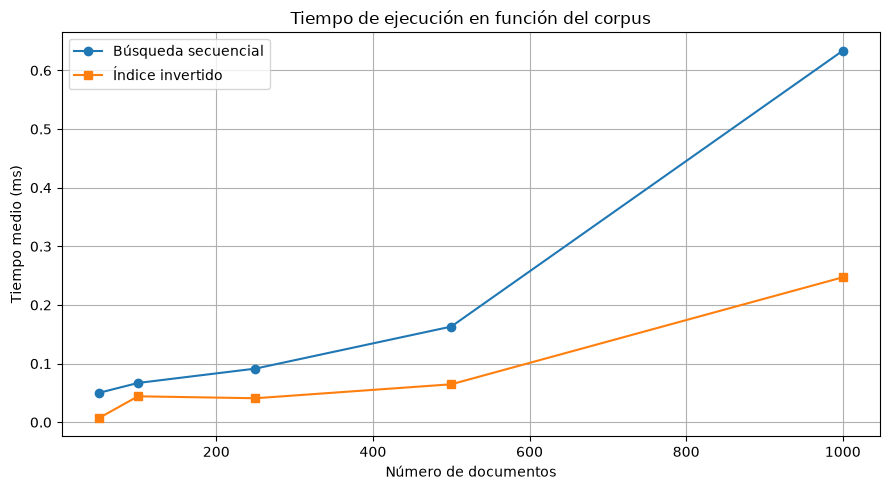

In [48]:
tamano_corpus = [50, 100, 250, 500, 1000]
consulta_experimento = "the"

documentos_lista = list(documentos_grandes.items())
resultados_escalabilidad = []

for n in tamano_corpus:
    subconjunto = dict(documentos_lista[:n])

    if not subconjunto:
        continue

    indice_subconjunto = construir_indice(subconjunto)

    resultados_escalabilidad.append({
        "Documentos": len(subconjunto),
        "Tokens": sum(map(len, subconjunto.values())),
        "Secuencial (ms)": medir_tiempo(
            _busqueda_secuencial_token, tokenizar(consulta_experimento)[0], subconjunto
        ),
        "Índice (ms)": medir_tiempo(
            _busqueda_indice_token, tokenizar(consulta_experimento)[0], indice_subconjunto
        )
    })

df_escalabilidad = pd.DataFrame(resultados_escalabilidad)
display(df_escalabilidad)

plt.figure(figsize=(9, 5))
plt.plot(
    df_escalabilidad["Documentos"],
    df_escalabilidad["Secuencial (ms)"],
    marker="o", label="Búsqueda secuencial"
)
plt.plot(
    df_escalabilidad["Documentos"],
    df_escalabilidad["Índice (ms)"],
    marker="s", label="Índice invertido"
)
plt.xlabel("Número de documentos")
plt.ylabel("Tiempo medio (ms)")
plt.title("Tiempo de ejecución en función del corpus")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

**9. Estimación de una función de tiempo**

Utilizando los resultados experimentales, determine una función:

$t=f(n)$

para cada método de recuperación.

Como primera aproximación, utilice un ajuste lineal por mínimos cuadrados:

$t(n)=an+b$

Estime los parámetros $a$ y $b$, reporte el coeficiente de determinación $R^2$ y represente las funciones ajustadas junto a los datos experimentales.

Explique si el modelo lineal representa adecuadamente las mediciones y cómo se relaciona con la complejidad computacional de cada algoritmo.

Secuencial: t(n) = 0.00060574n + -0.029114
R² secuencial: 0.916748
Índice: t(n) = 0.00023387n + -0.008041
R² índice: 0.907896


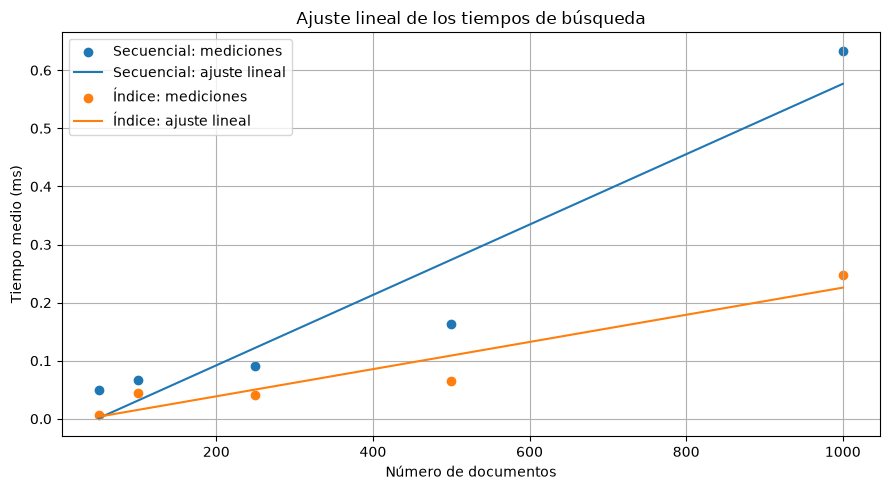

In [49]:
x = df_escalabilidad["Documentos"].to_numpy(dtype=float)
y_sec = df_escalabilidad["Secuencial (ms)"].to_numpy()
y_inv = df_escalabilidad["Índice (ms)"].to_numpy()


def ajustar_lineal(x, y):
    a, b = np.polyfit(x, y, 1)
    pred = a * x + b
    ss_res = np.sum((y - pred) ** 2)
    ss_tot = np.sum((y - np.mean(y)) ** 2)
    r2 = 1 - ss_res / ss_tot if ss_tot != 0 else float("nan")
    return a, b, r2, pred


a_sec, b_sec, r2_sec, pred_sec = ajustar_lineal(x, y_sec)
a_inv, b_inv, r2_inv, pred_inv = ajustar_lineal(x, y_inv)

print(f"Secuencial: t(n) = {a_sec:.8f}n + {b_sec:.6f}")
print(f"R² secuencial: {r2_sec:.6f}")
print(f"Índice: t(n) = {a_inv:.8f}n + {b_inv:.6f}")
print(f"R² índice: {r2_inv:.6f}")

plt.figure(figsize=(9, 5))
plt.scatter(x, y_sec, label="Secuencial: mediciones")
plt.plot(x, pred_sec, label="Secuencial: ajuste lineal")
plt.scatter(x, y_inv, label="Índice: mediciones")
plt.plot(x, pred_inv, label="Índice: ajuste lineal")
plt.xlabel("Número de documentos")
plt.ylabel("Tiempo medio (ms)")
plt.title("Ajuste lineal de los tiempos de búsqueda")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()


## Revisión de cumplimiento y análisis de resultados

### Comprobación de actividades

- **Parte A, preparación:** se cargan los 18 documentos de NLTK, se reportan caracteres y tokens por documento y se aplica minúscula más extracción de secuencias ASCII alfanuméricas (`[a-z0-9]+`). La misma función normaliza documentos y consultas; se conservan números y se eliminan puntuación y caracteres no ASCII.
- **Búsqueda secuencial y tiempos:** se usan los dos `for` anidados requeridos y se prueban términos frecuentes, menos frecuentes e inexistentes. Las consultas se normalizan antes de cronometrar; el cronómetro mide 30 repeticiones y reporta su media en milisegundos.
- **Índice y comparación:** el índice almacena para cada término los documentos que lo contienen. Se muestran postings y DF; se implementan consultas de término, AND, OR y NOT. La comparación verifica igualdad de resultados para las mismas consultas.
- **Parte B:** el ZIP contiene un TAR interno. La inspección registró 78.145 archivos TXT; la deduplicación por nombre no redujo esa cantidad. Se procesó un subconjunto de 1.000 documentos, con 71.962.446 tokens, y los resultados previos muestran coincidencia entre métodos. El archivo comprimido local ocupa 11.322.987.679 bytes (aprox. 10,54 GiB).
- **Parte C:** se midieron cinco tamaños (50, 100, 250, 500 y 1.000 documentos) y se graficaron ambos métodos; también se ajustó una recta y se calculó R². El notebook no reporta memoria RAM ni espacio temporal descomprimido, por lo que esos recursos quedan sin medir y no deben inferirse solo del tamaño comprimido.

### Respuestas e interpretación

En el corpus pequeño, el término `the` aparece en los 18 documentos (DF=18); `love`, en 15 (DF=15); `war`, en 10 (DF=10); el término inexistente tiene DF=0. Las pruebas de la Parte A confirman igualdad de resultados entre búsqueda secuencial e índice para las consultas evaluadas.

En el corpus grande, el índice evita recorrer los tokens de todos los documentos en cada consulta. Su construcción tiene un costo inicial y consume memoria para almacenar términos y postings; por eso la comparación de consulta debe entenderse separada del costo de construir el índice. La secuencial tiende a crecer con el volumen de tokens examinado, mientras que la búsqueda indexada depende principalmente de localizar el término y devolver su lista de postings. En la tabla de escalabilidad el tamaño en documentos también aumenta en tokens, de modo que ambas variables están relacionadas.

El ajuste lineal obtenido sobre cinco tamaños describe una tendencia, no una ley exacta. En la ejecución actual, el ajuste dio R²=0,916748 para secuencial y R²=0,907896 para índice. La búsqueda secuencial puede aproximarse a O(T) por consulta, donde T es el número de tokens revisados; el acceso al índice por término se aproxima a O(1) para localizar la clave, más el costo de devolver sus postings. El ajuste del índice contra número de documentos puede aparentar crecimiento porque los postings y el vocabulario también crecen. Las mediciones son sensibles a caché, carga del sistema y variabilidad entre ejecuciones.

**Nota de reproducibilidad:** se corrigió la importación de `Path` y se separó la normalización de la consulta del segmento cronometrado. Por ello, vuelva a ejecutar las celdas 1–18 para actualizar todas las salidas y gráficas con esta versión del código. La carga de los 1.000 documentos puede requerir varios minutos y una cantidad considerable de RAM; no se reprocesaron automáticamente los 11,3 GB durante esta revisión.

## Acuerdo de uso de inteligencia artificial

Declaro que utilicé inteligencia artificial como apoyo para revisar la estructura del notebook, detectar inconsistencias entre las instrucciones y el código, proponer correcciones de reproducibilidad y mejorar la redacción del análisis. La IA no sustituye la comprensión ni la responsabilidad del estudiante: revisé las sugerencias y debo ejecutar el notebook, comprobar sus resultados, explicar el funcionamiento de los algoritmos y citar cualquier fuente externa utilizada. Asumo la autoría y responsabilidad académica del trabajo final y me comprometo a no presentar como verificados resultados que no haya reproducido.

**Justificación:** el uso fue de asistencia técnica y editorial para localizar errores y hacer explícitos los límites de las mediciones. La interpretación se apoya en los resultados guardados y en la complejidad esperada de los algoritmos; los datos de RAM y almacenamiento temporal no se inventaron. La ejecución final debe confirmarse en el entorno donde se entregará el notebook.